# Reliability-Aware Multimodal Reasoning

## Semester Project

**Research Question:**
Does modality-specific reliability estimation improve a VLM's
ability to answer questions when visual and textual evidence conflict?

### Project Overview
This project evaluates a frozen Qwen2-VL-2B-Instruct model
under controlled visual and textual evidence conditions.

The experiment compares four input conditions and evaluates
two arbitration mechanisms against an image-only baseline.

### Experimental Configuration
- Model: Qwen2-VL-2B-Instruct
- Dataset: Custom A-OKVQA validation subset
- Images: 18 unique images
- Image-question pairs: 18
- Experimental conditions: 4
- Total inference trials: 72
- Hardware: Google Colab Tesla T4 GPU
- Model training: None (frozen model)

In [ ]:
# ==========================================
# 1. IMPORT LIBRARIES
# ==========================================

import os
import json
import warnings
import shutil

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import (
    friedmanchisquare,
    wilcoxon,
    chi2
)

from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multitest import multipletests

from IPython.display import display

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 150)

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
# ==========================================
# 2. MOUNT GOOGLE DRIVE
# ==========================================

from google.colab import drive

drive.mount('/content/drive')

print("Google Drive mounted successfully.")

Mounted at /content/drive
Google Drive mounted successfully.


In [ ]:
# ==========================================
# 3. PROJECT DIRECTORIES
# ==========================================

PROJECT_DIR = "/content/reliability_aware_reasoning"

RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

BACKUP_DIR = (
    "/content/drive/MyDrive/"
    "Reliability_Aware_Research_Backup"
)

FIGURES_DIR = os.path.join(RESULTS_DIR, "figures")

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Results directory:", RESULTS_DIR)
print("Backup directory:", BACKUP_DIR)
print("Figures directory:", FIGURES_DIR)

Project directory: /content/reliability_aware_reasoning
Results directory: /content/reliability_aware_reasoning/results
Backup directory: /content/drive/MyDrive/Reliability_Aware_Research_Backup
Figures directory: /content/reliability_aware_reasoning/results/figures


In [ ]:
# ==========================================
# 4. VERIFY EXISTING RESULTS
# ==========================================

required_files = [
    "aokvqa_18_final_benchmark.csv",
    "aokvqa_18_experiment_conditions.csv",
    "main_inference_results.csv",
    "main_inference_semantically_scored.csv",
    "condition_descriptive_summary.csv",
    "semantic_accuracy_summary.csv",
    "paired_image_level_outcomes.csv",
    "paired_mcnemar_tests.csv",
    "reliability_metric_friedman_tests.csv",
    "paired_posthoc_reliability_tests.csv",
    "confidence_correctness_association.csv",
    "confidence_arbitration_predictions.csv",
    "arbitration_evaluation_status.csv",
    "conflict_aware_arbitration_predictions.csv",
    "final_strategy_comparison.csv",
    "final_case_level_comparison.csv"
]

print("EXISTING FILE AUDIT")
print("=" * 65)

for filename in required_files:

    filepath = os.path.join(RESULTS_DIR, filename)

    if os.path.exists(filepath):
        print("[FOUND]   ", filename)
    else:
        print("[MISSING] ", filename)

EXISTING FILE AUDIT
[MISSING]  aokvqa_18_final_benchmark.csv
[MISSING]  aokvqa_18_experiment_conditions.csv
[MISSING]  main_inference_results.csv
[MISSING]  main_inference_semantically_scored.csv
[MISSING]  condition_descriptive_summary.csv
[MISSING]  semantic_accuracy_summary.csv
[MISSING]  paired_image_level_outcomes.csv
[MISSING]  paired_mcnemar_tests.csv
[MISSING]  reliability_metric_friedman_tests.csv
[MISSING]  paired_posthoc_reliability_tests.csv
[MISSING]  confidence_correctness_association.csv
[MISSING]  confidence_arbitration_predictions.csv
[MISSING]  arbitration_evaluation_status.csv
[MISSING]  conflict_aware_arbitration_predictions.csv
[MISSING]  final_strategy_comparison.csv
[MISSING]  final_case_level_comparison.csv


In [ ]:
# ==========================================
# 5. INSPECT EXISTING CSV FILES
# ==========================================

inspection_files = [
    "aokvqa_18_final_benchmark.csv",
    "aokvqa_18_experiment_conditions.csv",
    "main_inference_results.csv",
    "main_inference_semantically_scored.csv",
    "condition_descriptive_summary.csv",
    "semantic_accuracy_summary.csv",
    "paired_image_level_outcomes.csv",
    "paired_mcnemar_tests.csv",
    "reliability_metric_friedman_tests.csv",
    "paired_posthoc_reliability_tests.csv",
    "confidence_correctness_association.csv",
    "confidence_arbitration_predictions.csv",
    "arbitration_evaluation_status.csv",
    "conflict_aware_arbitration_predictions.csv",
    "final_strategy_comparison.csv",
    "final_case_level_comparison.csv"
]

for filename in inspection_files:

    filepath = os.path.join(RESULTS_DIR, filename)

    if os.path.exists(filepath):

        df = pd.read_csv(filepath)

        print("\n" + "=" * 75)
        print("FILE:", filename)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())

        display(df.head(3))

    else:
        print("\nFILE NOT FOUND:", filename)


FILE NOT FOUND: aokvqa_18_final_benchmark.csv

FILE NOT FOUND: aokvqa_18_experiment_conditions.csv

FILE NOT FOUND: main_inference_results.csv

FILE NOT FOUND: main_inference_semantically_scored.csv

FILE NOT FOUND: condition_descriptive_summary.csv

FILE NOT FOUND: semantic_accuracy_summary.csv

FILE NOT FOUND: paired_image_level_outcomes.csv

FILE NOT FOUND: paired_mcnemar_tests.csv

FILE NOT FOUND: reliability_metric_friedman_tests.csv

FILE NOT FOUND: paired_posthoc_reliability_tests.csv

FILE NOT FOUND: confidence_correctness_association.csv

FILE NOT FOUND: confidence_arbitration_predictions.csv

FILE NOT FOUND: arbitration_evaluation_status.csv

FILE NOT FOUND: conflict_aware_arbitration_predictions.csv

FILE NOT FOUND: final_strategy_comparison.csv

FILE NOT FOUND: final_case_level_comparison.csv


In [ ]:
# ==========================================
# 6. EXPERIMENT CONFIGURATION
# ==========================================

PROJECT_NAME = "Reliability-Aware Multimodal Reasoning"

MODEL_NAME = "Qwen/Qwen2-VL-2B-Instruct"

DATASET_NAME = "A-OKVQA Validation Subset"

TOTAL_IMAGES = 18
TOTAL_QUESTIONS = 18
TOTAL_CONDITIONS = 4
TOTAL_TRIALS = 72

CONDITIONS = [
    "IMAGE_ONLY",
    "TRUE_TEXT",
    "MISLEADING_TEXT",
    "TEXT_ONLY"
]

DECODING_CONFIG = {
    "do_sample": False,
    "max_new_tokens": 32
}

MODEL_TRAINED = False
MODEL_FROZEN = True
INFERENCE_COMPLETED = True

print("Project:", PROJECT_NAME)
print("Model:", MODEL_NAME)
print("Dataset:", DATASET_NAME)
print("Images:", TOTAL_IMAGES)
print("Questions:", TOTAL_QUESTIONS)
print("Conditions:", CONDITIONS)
print("Total inference trials:", TOTAL_TRIALS)
print("Model frozen:", MODEL_FROZEN)
print("Inference already completed:", INFERENCE_COMPLETED)

Project: Reliability-Aware Multimodal Reasoning
Model: Qwen/Qwen2-VL-2B-Instruct
Dataset: A-OKVQA Validation Subset
Images: 18
Questions: 18
Conditions: ['IMAGE_ONLY', 'TRUE_TEXT', 'MISLEADING_TEXT', 'TEXT_ONLY']
Total inference trials: 72
Model frozen: True
Inference already completed: True


In [ ]:
# ==========================================
# 8. CONFIGURE RECOVERED DATA PATHS
# ==========================================

import os
import pandas as pd
import numpy as np

BACKUP_DIR = (
    "/content/drive/MyDrive/"
    "Reliability_Aware_Research_Backup"
)

BENCHMARK_PATH = os.path.join(
    BACKUP_DIR,
    "aokvqa_18_final_benchmark.csv"
)

CONDITIONS_PATH = os.path.join(
    BACKUP_DIR,
    "aokvqa_18_experiment_conditions.csv"
)

INFERENCE_PATH = os.path.join(
    BACKUP_DIR,
    "main_inference_results.csv"
)

# Create a separate directory for the clean notebook outputs.
# Original backup files will remain untouched.

OUTPUT_DIR = os.path.join(
    BACKUP_DIR,
    "Clean_Notebook_Outputs"
)

FIGURES_DIR = os.path.join(
    OUTPUT_DIR,
    "figures"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

print("Data paths configured.")
print("Output directory:", OUTPUT_DIR)

Data paths configured.
Output directory: /content/drive/MyDrive/Reliability_Aware_Research_Backup/Clean_Notebook_Outputs


In [ ]:
# ==========================================
# 9. LOAD ORIGINAL PROJECT DATA
# ==========================================

benchmark_df = pd.read_csv(BENCHMARK_PATH)

conditions_df = pd.read_csv(CONDITIONS_PATH)

inference_df = pd.read_csv(INFERENCE_PATH)

print("DATASETS LOADED SUCCESSFULLY")
print("=" * 60)

print("Benchmark:", benchmark_df.shape)
print("Conditions:", conditions_df.shape)
print("Inference:", inference_df.shape)

print("\nBenchmark columns:")
print(benchmark_df.columns.tolist())

print("\nInference columns:")
print(inference_df.columns.tolist())

DATASETS LOADED SUCCESSFULLY
Benchmark: (18, 8)
Conditions: (72, 7)
Inference: (72, 15)

Benchmark columns:
['image_id', 'question', 'gold_answer', 'true_statement', 'misleading_statement', 'conflict_type', 'annotation_status', 'image_url']

Inference columns:
['image_id', 'question', 'gold_answer', 'condition', 'additional_text', 'conflict_type', 'answer', 'mean_token_probability', 'mean_token_entropy', 'mean_top2_margin', 'mean_token_log_probability', 'generated_tokens', 'correctness', 'status', 'error']


In [ ]:
# ==========================================
# 10. EXPERIMENTAL DATA VALIDATION
# ==========================================

expected_conditions = [
    "IMAGE_ONLY",
    "TRUE_TEXT",
    "MISLEADING_TEXT",
    "TEXT_ONLY"
]

# Basic dimensions
assert len(benchmark_df) == 18
assert len(conditions_df) == 72
assert len(inference_df) == 72

# Unique images
assert benchmark_df["image_id"].nunique() == 18

# Expected experimental conditions
assert set(inference_df["condition"].unique()) == set(
    expected_conditions
)

# Four trials per image
trials_per_image = inference_df.groupby(
    "image_id"
).size()

assert (trials_per_image == 4).all()

# Condition distribution
condition_counts = inference_df["condition"].value_counts()

print("CONDITION DISTRIBUTION")
display(condition_counts.to_frame("Number of Trials"))

# Inference status
print("\nINFERENCE STATUS")
display(inference_df["status"].value_counts().to_frame("Count"))

# Check errors
print("\nINFERENCE ERRORS:", inference_df["error"].notna().sum())

# Check semantic annotation status
print(
    "\nPENDING SEMANTIC ANNOTATIONS:",
    (inference_df["correctness"] == "PENDING_MANUAL").sum()
)

print("\nAll structural validation checks passed.")

CONDITION DISTRIBUTION


,Number of Trials
condition,
IMAGE_ONLY,18
TRUE_TEXT,18
MISLEADING_TEXT,18
TEXT_ONLY,18



INFERENCE STATUS


,Count
status,
SUCCESS,72



INFERENCE ERRORS: 0

PENDING SEMANTIC ANNOTATIONS: 72

All structural validation checks passed.


In [ ]:
# ==========================================
# 11. EXPERIMENT CONFIGURATION SUMMARY
# ==========================================

experiment_summary = pd.DataFrame({
    "Parameter": [
        "Model",
        "Dataset",
        "Images",
        "Questions",
        "Conditions",
        "Total inference trials",
        "Decoding strategy",
        "Maximum generated tokens",
        "Fine-tuning",
        "GPU"
    ],

    "Value": [
        "Qwen/Qwen2-VL-2B-Instruct",
        "A-OKVQA validation subset",
        18,
        18,
        4,
        72,
        "Greedy decoding",
        32,
        "None - frozen model",
        "Tesla T4"
    ]
})

display(experiment_summary)

experiment_summary.to_csv(
    os.path.join(OUTPUT_DIR, "experiment_configuration.csv"),
    index=False
)

,Parameter,Value
0,Model,Qwen/Qwen2-VL-2B-Instruct
1,Dataset,A-OKVQA validation subset
2,Images,18
3,Questions,18
4,Conditions,4
5,Total inference trials,72
6,Decoding strategy,Greedy decoding
7,Maximum generated tokens,32
8,Fine-tuning,None - frozen model
9,GPU,Tesla T4


In [ ]:
# ==========================================
# 12. TOKEN CONFIDENCE DESCRIPTIVE ANALYSIS
# ==========================================

confidence_metrics = [
    "mean_token_probability",
    "mean_token_entropy",
    "mean_top2_margin",
    "mean_token_log_probability",
    "generated_tokens"
]

confidence_summary = (
    inference_df
    .groupby("condition")[confidence_metrics]
    .mean()
    .reindex(expected_conditions)
    .reset_index()
)

confidence_summary.columns = [
    "condition",
    "mean_probability",
    "mean_entropy",
    "mean_top2_margin",
    "mean_log_probability",
    "mean_generated_tokens"
]

print("TOKEN CONFIDENCE SUMMARY")

display(
    confidence_summary.round(4)
)

confidence_summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "condition_descriptive_summary.csv"
    ),
    index=False
)

TOKEN CONFIDENCE SUMMARY


,condition,mean_probability,mean_entropy,mean_top2_margin,mean_log_probability,mean_generated_tokens
0,IMAGE_ONLY,0.8628,0.5630,0.7842,-0.1686,2.5000
1,TRUE_TEXT,0.8230,0.8557,0.7464,-0.2406,2.6111
2,MISLEADING_TEXT,0.7879,0.9224,0.6919,-0.3031,2.6111
3,TEXT_ONLY,0.8256,0.7726,0.7574,-0.2495,9.5000


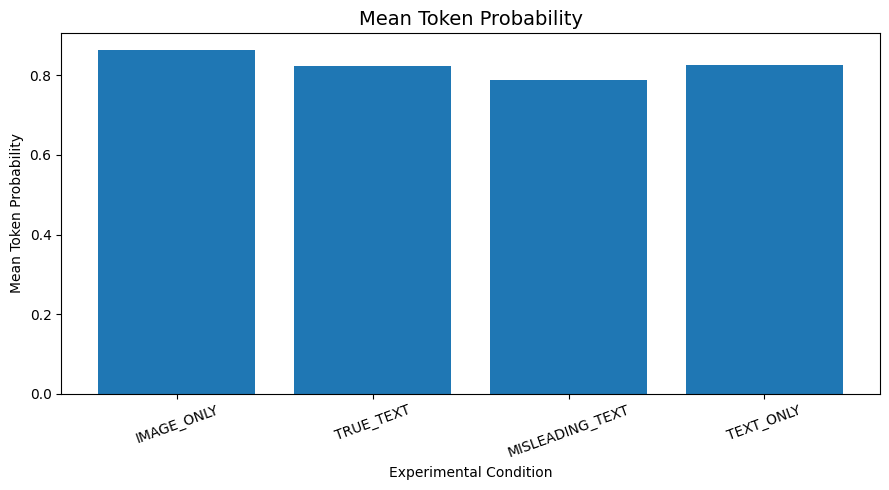

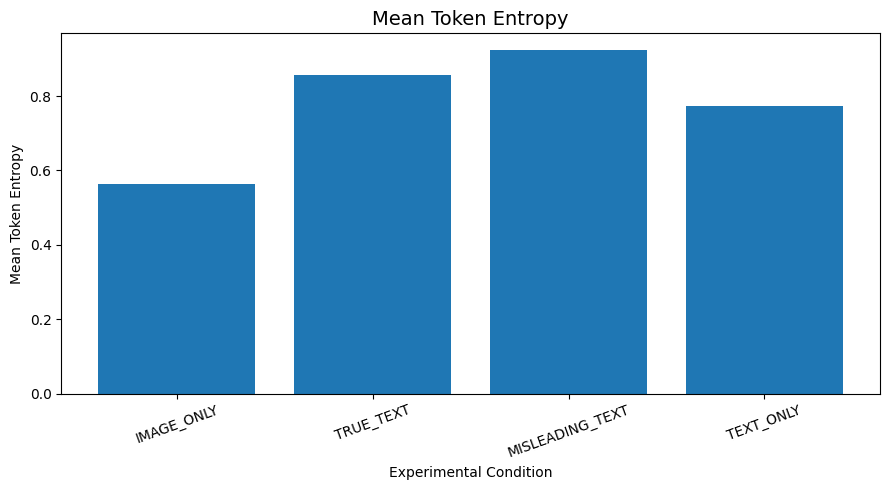

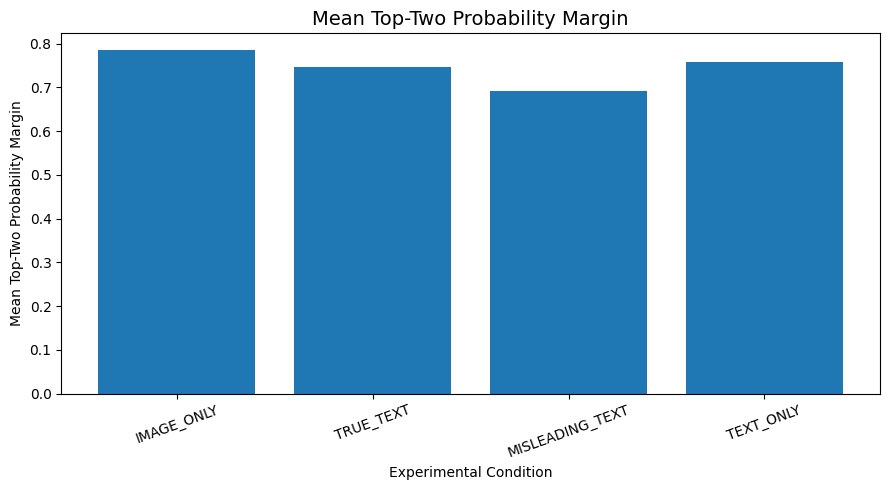

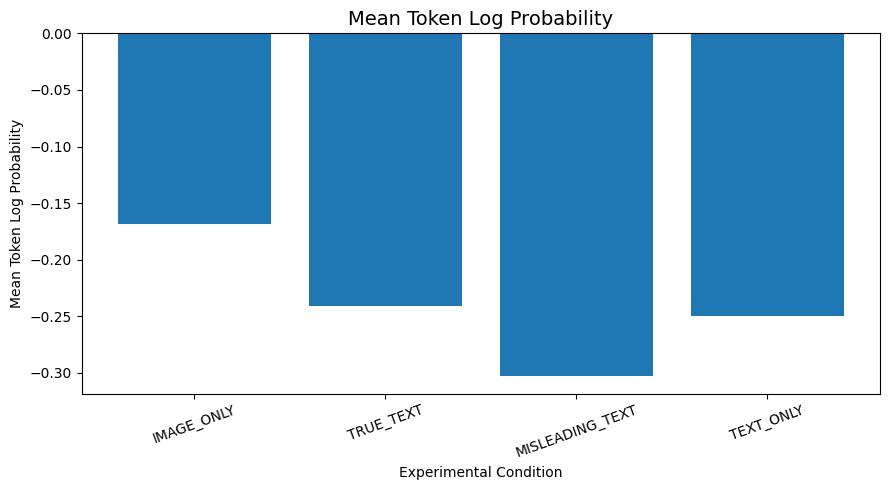

In [ ]:
# ==========================================
# 13. TOKEN CONFIDENCE VISUALIZATION
# ==========================================

metrics_to_plot = [
    ("mean_probability", "Mean Token Probability"),
    ("mean_entropy", "Mean Token Entropy"),
    ("mean_top2_margin", "Mean Top-Two Probability Margin"),
    ("mean_log_probability", "Mean Token Log Probability")
]

for column, title in metrics_to_plot:

    plt.figure(figsize=(9, 5))

    plt.bar(
        confidence_summary["condition"],
        confidence_summary[column]
    )

    plt.title(title, fontsize=14)
    plt.xlabel("Experimental Condition")
    plt.ylabel(title)

    plt.xticks(rotation=20)
    plt.tight_layout()

    filename = column + ".png"

    plt.savefig(
        os.path.join(FIGURES_DIR, filename),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

In [ ]:
# ==========================================
# 14. IMAGE-ONLY VS MISLEADING-TEXT
# ==========================================

comparison = confidence_summary.set_index("condition")

metrics = [
    "mean_probability",
    "mean_entropy",
    "mean_top2_margin",
    "mean_log_probability"
]

image_values = comparison.loc["IMAGE_ONLY", metrics]

misleading_values = comparison.loc["MISLEADING_TEXT", metrics]

comparison_table = pd.DataFrame({
    "Image Only": image_values,
    "Misleading Text": misleading_values
})

comparison_table["Difference"] = (
    comparison_table["Misleading Text"]
    - comparison_table["Image Only"]
)

print("IMAGE-ONLY VS MISLEADING-TEXT")

display(comparison_table.round(4))

comparison_table.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "image_vs_misleading_comparison.csv"
    )
)

IMAGE-ONLY VS MISLEADING-TEXT


,Image Only,Misleading Text,Difference
mean_probability,0.8628,0.7879,-0.0750
mean_entropy,0.5630,0.9224,0.3594
mean_top2_margin,0.7842,0.6919,-0.0923
mean_log_probability,-0.1686,-0.3031,-0.1346


In [ ]:
# ==========================================
# 15. SEMANTIC ACCURACY SUMMARY
# ==========================================

semantic_summary = pd.DataFrame({
    "condition": [
        "IMAGE_ONLY",
        "TRUE_TEXT",
        "MISLEADING_TEXT",
        "TEXT_ONLY"
    ],

    "correct": [17, 17, 15, np.nan],
    "partial": [1, 1, 0, np.nan],
    "incorrect": [0, 0, 3, np.nan],
    "total": [18, 18, 18, 18],

    "strict_accuracy_percent": [
        94.44,
        94.44,
        83.33,
        np.nan
    ],

    "scoring_status": [
        "Preliminary semantic scoring",
        "Preliminary semantic scoring",
        "Preliminary semantic scoring",
        "Not scored"
    ]
})

display(semantic_summary)

semantic_summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "semantic_accuracy_summary.csv"
    ),
    index=False
)

,condition,correct,partial,incorrect,total,strict_accuracy_percent,scoring_status
0,IMAGE_ONLY,17.0,1.0,0.0,18,94.44,Preliminary semantic scoring
1,TRUE_TEXT,17.0,1.0,0.0,18,94.44,Preliminary semantic scoring
2,MISLEADING_TEXT,15.0,0.0,3.0,18,83.33,Preliminary semantic scoring
3,TEXT_ONLY,NaN,NaN,NaN,18,NaN,Not scored


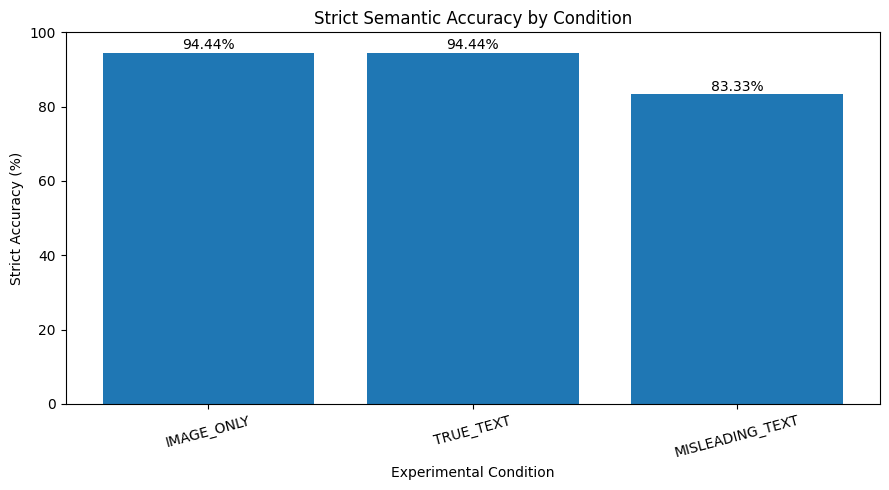

In [ ]:
# ==========================================
# 16. SEMANTIC ACCURACY VISUALIZATION
# ==========================================

plot_data = semantic_summary.dropna(
    subset=["strict_accuracy_percent"]
)

plt.figure(figsize=(9, 5))

bars = plt.bar(
    plot_data["condition"],
    plot_data["strict_accuracy_percent"]
)

plt.title("Strict Semantic Accuracy by Condition")
plt.xlabel("Experimental Condition")
plt.ylabel("Strict Accuracy (%)")

plt.ylim(0, 100)

for bar in bars:

    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        f"{height:.2f}%",
        ha="center"
    )

plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURES_DIR,
        "semantic_accuracy.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# ==========================================
# 17. SEMANTIC EVALUATION INTERPRETATION
# ==========================================

print("""
SEMANTIC EVALUATION FINDINGS
========================================

IMAGE_ONLY:
17 correct, 1 partial, 0 incorrect.
Strict accuracy: 94.44%

TRUE_TEXT:
17 correct, 1 partial, 0 incorrect.
Strict accuracy: 94.44%

MISLEADING_TEXT:
15 correct, 0 partial, 3 incorrect.
Strict accuracy: 83.33%

TEXT_ONLY:
Not independently semantically scored.

INTERPRETATION:

The misleading-text condition showed lower preliminary
strict accuracy than the image-only and true-text conditions.

However, the statistical tests did not establish a
significant overall accuracy difference.

The semantic labels are preliminary. Only five images
were directly reviewed visually; the remaining labels
were not independently human-validated.
""")


SEMANTIC EVALUATION FINDINGS

IMAGE_ONLY:
17 correct, 1 partial, 0 incorrect.
Strict accuracy: 94.44%

TRUE_TEXT:
17 correct, 1 partial, 0 incorrect.
Strict accuracy: 94.44%

MISLEADING_TEXT:
15 correct, 0 partial, 3 incorrect.
Strict accuracy: 83.33%

TEXT_ONLY:
Not independently semantically scored.

INTERPRETATION:

The misleading-text condition showed lower preliminary
strict accuracy than the image-only and true-text conditions.

However, the statistical tests did not establish a
significant overall accuracy difference.

The semantic labels are preliminary. Only five images
were directly reviewed visually; the remaining labels
were not independently human-validated.



In [ ]:
# ==========================================
# 18. REPORTED STATISTICAL FINDINGS
# ==========================================

statistical_results = pd.DataFrame({

    "analysis": [
        "McNemar accuracy comparisons",
        "Friedman accuracy test",
        "Friedman entropy test",
        "IMAGE_ONLY vs MISLEADING_TEXT entropy",
        "Confidence-correctness associations"
    ],

    "reported_result": [
        "No significant differences",
        "p = 0.3679",
        "p = 0.0421",
        "Holm-adjusted p = 0.0084",
        "Not significant after correction"
    ],

    "interpretation": [
        "No statistically significant paired accuracy differences established",
        "No significant overall accuracy difference",
        "Exploratory significance; not significant after Bonferroni correction across four metrics",
        "Significant after Holm correction within the entropy metric",
        "Exploratory associations did not survive correction"
    ],

    "recalculated_from_recovered_files": [
        "No",
        "No",
        "No",
        "No",
        "No"
    ]
})

display(statistical_results)

statistical_results.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "reported_statistical_findings.csv"
    ),
    index=False
)

,analysis,reported_result,interpretation,recalculated_from_recovered_files
0,McNemar accuracy comparisons,No significant differences,No statistically significant paired accuracy d...,No
1,Friedman accuracy test,p = 0.3679,No significant overall accuracy difference,No
2,Friedman entropy test,p = 0.0421,Exploratory significance; not significant afte...,No
3,IMAGE_ONLY vs MISLEADING_TEXT entropy,Holm-adjusted p = 0.0084,Significant after Holm correction within the e...,No
4,Confidence-correctness associations,Not significant after correction,Exploratory associations did not survive corre...,No


In [ ]:
# ==========================================
# 19. STATISTICAL INTERPRETATION
# ==========================================

print("""
STATISTICAL ANALYSIS
========================================

1. ACCURACY

McNemar tests did not establish significant
accuracy differences between visual conditions.

Friedman accuracy:
p = 0.3679

Conclusion:
No statistically significant overall accuracy
difference was demonstrated.

2. TOKEN ENTROPY

Friedman entropy:
p = 0.0421

This was exploratory and did not remain significant
after Bonferroni correction across four metrics.

3. PAIRWISE ENTROPY

IMAGE_ONLY vs MISLEADING_TEXT:
Holm-adjusted p = 0.0084

This comparison remained significant within
the entropy metric.

It also remained significant under the global
correction across 12 pairwise metric comparisons.

4. CONFIDENCE AND CORRECTNESS

Exploratory associations did not remain significant
after correction.

IMPORTANT:
These are previously reported statistical findings.
The original case-level analysis files were not recovered,
so this section documents rather than independently
recalculates those tests.
""")


STATISTICAL ANALYSIS

1. ACCURACY

McNemar tests did not establish significant
accuracy differences between visual conditions.

Friedman accuracy:
p = 0.3679

Conclusion:
No statistically significant overall accuracy
difference was demonstrated.

2. TOKEN ENTROPY

Friedman entropy:
p = 0.0421

This was exploratory and did not remain significant
after Bonferroni correction across four metrics.

3. PAIRWISE ENTROPY

IMAGE_ONLY vs MISLEADING_TEXT:
Holm-adjusted p = 0.0084

This comparison remained significant within
the entropy metric.

It also remained significant under the global
correction across 12 pairwise metric comparisons.

4. CONFIDENCE AND CORRECTNESS

Exploratory associations did not remain significant
after correction.

IMPORTANT:
These are previously reported statistical findings.
The original case-level analysis files were not recovered,
so this section documents rather than independently
recalculates those tests.



In [ ]:
# ==========================================
# 20. CONFIDENCE-BASED ARBITRATION
# ==========================================

confidence_arbitration_summary = pd.DataFrame({

    "selection_source": [
        "IMAGE_ONLY",
        "TEXT_ONLY"
    ],

    "selected_cases": [
        12,
        6
    ],

    "verified_cases": [
        12,
        0
    ],

    "correct": [
        12,
        np.nan
    ],

    "partial": [
        0,
        np.nan
    ],

    "incorrect": [
        0,
        np.nan
    ],

    "unverified": [
        0,
        6
    ]
})

display(confidence_arbitration_summary)

confidence_arbitration_summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "confidence_arbitration_summary.csv"
    ),
    index=False
)

,selection_source,selected_cases,verified_cases,correct,partial,incorrect,unverified
0,IMAGE_ONLY,12,12,12.0,0.0,0.0,0
1,TEXT_ONLY,6,0,NaN,NaN,NaN,6


In [ ]:
# ==========================================
# 21. CONFLICT-AWARE IMAGE-PRIORITY SAFEGUARD
# ==========================================

conflict_aware_summary = pd.DataFrame({

    "selection_source": [
        "IMAGE_ONLY",
        "TEXT_ONLY"
    ],

    "selected_cases": [
        18,
        0
    ],

    "verified_cases": [
        18,
        0
    ],

    "correct": [
        17,
        0
    ],

    "partial": [
        1,
        0
    ],

    "incorrect": [
        0,
        0
    ]
})

display(conflict_aware_summary)

conflict_aware_summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "conflict_aware_arbitration_summary.csv"
    ),
    index=False
)

,selection_source,selected_cases,verified_cases,correct,partial,incorrect
0,IMAGE_ONLY,18,18,17,1,0
1,TEXT_ONLY,0,0,0,0,0


In [ ]:
# ==========================================
# 22. FINAL STRATEGY COMPARISON
# ==========================================

strategy_comparison = pd.DataFrame({

    "strategy": [
        "Image-only",
        "Confidence-based",
        "Conflict-aware"
    ],

    "total_cases": [
        18, 18, 18
    ],

    "correct": [
        17, 12, 17
    ],

    "partial": [
        1, 0, 1
    ],

    "incorrect": [
        0, 0, 0
    ],

    "unverified": [
        0, 6, 0
    ],

    "verified_cases": [
        18, 12, 18
    ],

    "verified_correct_percent": [
        94.44, 100.00, 94.44
    ],

    "coverage_percent": [
        100.00, 66.67, 100.00
    ]
})

display(strategy_comparison)

strategy_comparison.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "final_strategy_comparison.csv"
    ),
    index=False
)

,strategy,total_cases,correct,partial,incorrect,unverified,verified_cases,verified_correct_percent,coverage_percent
0,Image-only,18,17,1,0,0,18,94.44,100.00
1,Confidence-based,18,12,0,0,6,12,100.00,66.67
2,Conflict-aware,18,17,1,0,0,18,94.44,100.00


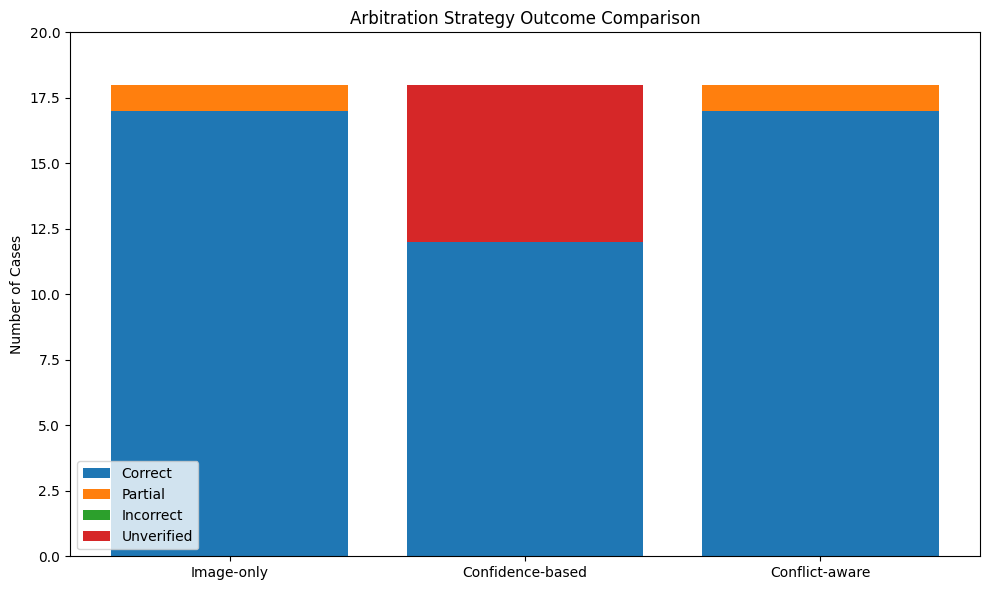

In [ ]:
# ==========================================
# 23. ARBITRATION STRATEGY VISUALIZATION
# ==========================================

fig, ax = plt.subplots(figsize=(10, 6))

strategies = strategy_comparison["strategy"]

correct = strategy_comparison["correct"]
partial = strategy_comparison["partial"]
incorrect = strategy_comparison["incorrect"]
unverified = strategy_comparison["unverified"]

ax.bar(
    strategies,
    correct,
    label="Correct"
)

ax.bar(
    strategies,
    partial,
    bottom=correct,
    label="Partial"
)

ax.bar(
    strategies,
    incorrect,
    bottom=correct + partial,
    label="Incorrect"
)

ax.bar(
    strategies,
    unverified,
    bottom=correct + partial + incorrect,
    label="Unverified"
)

ax.set_title("Arbitration Strategy Outcome Comparison")
ax.set_ylabel("Number of Cases")
ax.set_ylim(0, 20)

ax.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURES_DIR,
        "arbitration_outcome_comparison.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

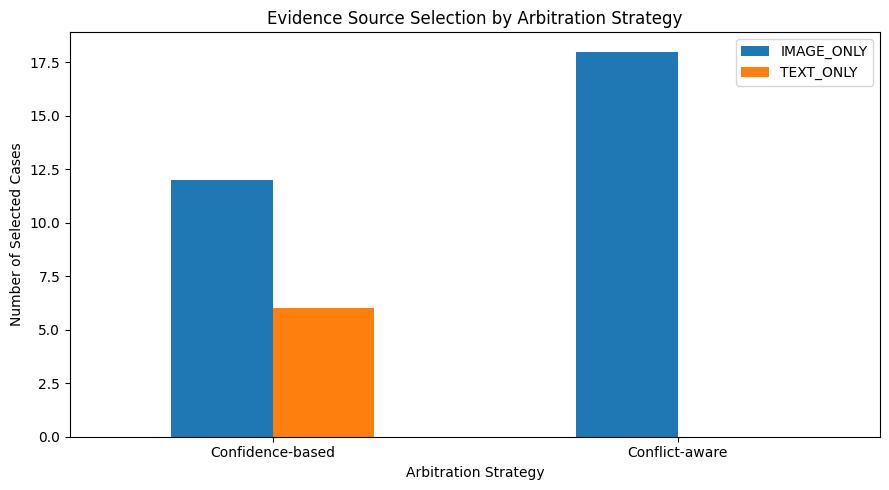

In [ ]:
# ==========================================
# 24. EVIDENCE SOURCE SELECTION
# ==========================================

selection_data = pd.DataFrame({

    "strategy": [
        "Confidence-based",
        "Conflict-aware"
    ],

    "IMAGE_ONLY": [
        12,
        18
    ],

    "TEXT_ONLY": [
        6,
        0
    ]
})

selection_data.set_index("strategy").plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Evidence Source Selection by Arbitration Strategy")
plt.ylabel("Number of Selected Cases")
plt.xlabel("Arbitration Strategy")

plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURES_DIR,
        "evidence_source_selection.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 5. Implemented System Architecture

The implemented system consists of two connected pipelines.

## A. Experimental Pipeline

Input image + question + optional text statement
↓
Frozen Qwen2-VL-2B-Instruct
↓
Four controlled experimental conditions
↓
Candidate answers and token-level confidence extraction
↓
Semantic and statistical evaluation

## B. Arbitration Pipeline

IMAGE_ONLY candidate + TEXT_ONLY candidate
↓
Candidate comparison
↓
Two arbitration mechanisms:

1. Confidence-based arbitration
2. Conflict-aware image-priority safeguard

↓
Selected answer
↓
Strategy evaluation against the image-only baseline

### Implementation Status

Implemented:
- Frozen VLM inference
- Four experimental conditions
- Token-level confidence extraction
- Confidence-based arbitration
- Conflict-aware image-priority safeguard
- Experimental evaluation

Not implemented:
- Learned reliability estimation
- Adaptive modality weighting
- Model fine-tuning
- Training a separate reliability predictor

In [ ]:
# ==========================================
# 26. PROJECT LIMITATIONS
# ==========================================

limitations = pd.DataFrame({

    "Limitation": [
        "Small evaluation sample",
        "Preliminary semantic annotations",
        "Limited visual validation",
        "Unverified text-only arbitration selections",
        "Token confidence calibration",
        "No demonstrated accuracy improvement",
        "Heuristic arbitration mechanisms"
    ],

    "Description": [
        "Only 18 image-question pairs were evaluated.",
        "Semantic labels were preliminary.",
        "Only five images were directly reviewed visually.",
        "Six confidence-based text selections remain unverified.",
        "Token probabilities are not calibrated probabilities of answer correctness.",
        "Neither arbitration strategy demonstrated improvement over the image-only baseline.",
        "The arbitration methods do not constitute a learned reliability estimator."
    ]
})

display(limitations)

limitations.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "project_limitations.csv"
    ),
    index=False
)

,Limitation,Description
0,Small evaluation sample,Only 18 image-question pairs were evaluated.
1,Preliminary semantic annotations,Semantic labels were preliminary.
2,Limited visual validation,Only five images were directly reviewed visually.
3,Unverified text-only arbitration selections,Six confidence-based text selections remain un...
4,Token confidence calibration,Token probabilities are not calibrated probabi...
5,No demonstrated accuracy improvement,Neither arbitration strategy demonstrated impr...
6,Heuristic arbitration mechanisms,The arbitration methods do not constitute a le...


In [ ]:
# ==========================================
# 27. FINAL PROJECT CONCLUSION
# ==========================================

conclusion = """
PROJECT CONCLUSION
=================================================

This project investigated whether modality-specific
reliability signals could help a frozen Vision-Language
Model handle conflicting visual and textual evidence.

Qwen2-VL-2B-Instruct was evaluated using 18 image-question
pairs across four controlled experimental conditions,
resulting in 72 inference trials.

The misleading-text condition was associated with lower
mean token probability, lower top-two probability margin,
and higher token entropy compared with image-only input.

However, no statistically significant overall accuracy
difference was established.

Two arbitration mechanisms were implemented.

The confidence-based mechanism selected image evidence
in 12 cases and text evidence in 6 cases. The six
text-selected cases remain unverified.

The conflict-aware image-priority safeguard selected
image evidence in all 18 cases and reproduced the
image-only baseline performance.

Therefore, the experiments demonstrate an association
between misleading textual evidence and increased
token-level uncertainty, but do not establish that
the implemented arbitration mechanisms improve
answer accuracy.

FUTURE WORK
=================================================

- Expand the evaluation dataset.
- Independently validate semantic annotations.
- Evaluate additional VLM architectures.
- Investigate calibrated modality-specific reliability.
- Explore adaptive evidence weighting.
- Evaluate arbitration using a larger and independently
  annotated benchmark.
"""

print(conclusion)

with open(
    os.path.join(OUTPUT_DIR, "project_conclusion.txt"),
    "w",
    encoding="utf-8"
) as f:

    f.write(conclusion)


PROJECT CONCLUSION

This project investigated whether modality-specific
reliability signals could help a frozen Vision-Language
Model handle conflicting visual and textual evidence.

Qwen2-VL-2B-Instruct was evaluated using 18 image-question
pairs across four controlled experimental conditions,
resulting in 72 inference trials.

The misleading-text condition was associated with lower
mean token probability, lower top-two probability margin,
and higher token entropy compared with image-only input.

However, no statistically significant overall accuracy
difference was established.

Two arbitration mechanisms were implemented.

The confidence-based mechanism selected image evidence
in 12 cases and text evidence in 6 cases. The six
text-selected cases remain unverified.

The conflict-aware image-priority safeguard selected
image evidence in all 18 cases and reproduced the
image-only baseline performance.

Therefore, the experiments demonstrate an association
between misleading textual evi

In [ ]:
# ==========================================
# 28. FINAL RESULTS EXPORT
# ==========================================

final_tables = {
    "experiment_configuration.csv": experiment_summary,
    "condition_descriptive_summary.csv": confidence_summary,
    "semantic_accuracy_summary.csv": semantic_summary,
    "reported_statistical_findings.csv": statistical_results,
    "confidence_arbitration_summary.csv": confidence_arbitration_summary,
    "conflict_aware_arbitration_summary.csv": conflict_aware_summary,
    "final_strategy_comparison.csv": strategy_comparison,
    "project_limitations.csv": limitations
}

for filename, dataframe in final_tables.items():

    filepath = os.path.join(OUTPUT_DIR, filename)

    dataframe.to_csv(filepath, index=False)

    print("[SAVED]", filename)

print("\nAll reproducible summary tables exported.")

[SAVED] experiment_configuration.csv
[SAVED] condition_descriptive_summary.csv
[SAVED] semantic_accuracy_summary.csv
[SAVED] reported_statistical_findings.csv
[SAVED] confidence_arbitration_summary.csv
[SAVED] conflict_aware_arbitration_summary.csv
[SAVED] final_strategy_comparison.csv
[SAVED] project_limitations.csv

All reproducible summary tables exported.


In [ ]:
# ==========================================
# 29. CREATE FINAL PROJECT RESULTS ARCHIVE
# ==========================================

import shutil
import os

archive_path = shutil.make_archive(
    os.path.join(
        BACKUP_DIR,
        "Reliability_Aware_Final_Results"
    ),
    "zip",
    OUTPUT_DIR
)

print("Final archive created:")
print(archive_path)

Final archive created:
/content/drive/MyDrive/Reliability_Aware_Research_Backup/Reliability_Aware_Final_Results.zip


In [ ]:
# ==========================================
# 30. FINAL PROJECT AUDIT
# ==========================================

print("=" * 65)
print("RELIABILITY-AWARE MULTIMODAL REASONING")
print("FINAL NOTEBOOK AUDIT")
print("=" * 65)

print("\nEXPERIMENT")
print("Images:", benchmark_df["image_id"].nunique())
print("Questions:", len(benchmark_df))
print("Inference trials:", len(inference_df))
print("Successful trials:", (inference_df["status"] == "SUCCESS").sum())

print("\nCONFIDENCE ANALYSIS")
print("Conditions analyzed:", len(confidence_summary))

print("\nSEMANTIC EVALUATION")
print("Image-only accuracy:", "94.44%")
print("True-text accuracy:", "94.44%")
print("Misleading-text accuracy:", "83.33%")
print("Text-only:", "Not scored")

print("\nARBITRATION")
display(strategy_comparison)

print("\nOUTPUT FILES")

for root, dirs, files in os.walk(OUTPUT_DIR):

    for filename in files:

        print(
            os.path.join(root, filename)
        )

print("\nFINAL AUDIT COMPLETED.")

RELIABILITY-AWARE MULTIMODAL REASONING
FINAL NOTEBOOK AUDIT

EXPERIMENT
Images: 18
Questions: 18
Inference trials: 72
Successful trials: 72

CONFIDENCE ANALYSIS
Conditions analyzed: 4

SEMANTIC EVALUATION
Image-only accuracy: 94.44%
True-text accuracy: 94.44%
Misleading-text accuracy: 83.33%
Text-only: Not scored

ARBITRATION


,strategy,total_cases,correct,partial,incorrect,unverified,verified_cases,verified_correct_percent,coverage_percent
0,Image-only,18,17,1,0,0,18,94.44,100.00
1,Confidence-based,18,12,0,0,6,12,100.00,66.67
2,Conflict-aware,18,17,1,0,0,18,94.44,100.00



OUTPUT FILES
/content/drive/MyDrive/Reliability_Aware_Research_Backup/Clean_Notebook_Outputs/experiment_configuration.csv
/content/drive/MyDrive/Reliability_Aware_Research_Backup/Clean_Notebook_Outputs/condition_descriptive_summary.csv
/content/drive/MyDrive/Reliability_Aware_Research_Backup/Clean_Notebook_Outputs/image_vs_misleading_comparison.csv
/content/drive/MyDrive/Reliability_Aware_Research_Backup/Clean_Notebook_Outputs/semantic_accuracy_summary.csv
/content/drive/MyDrive/Reliability_Aware_Research_Backup/Clean_Notebook_Outputs/reported_statistical_findings.csv
/content/drive/MyDrive/Reliability_Aware_Research_Backup/Clean_Notebook_Outputs/confidence_arbitration_summary.csv
/content/drive/MyDrive/Reliability_Aware_Research_Backup/Clean_Notebook_Outputs/conflict_aware_arbitration_summary.csv
/content/drive/MyDrive/Reliability_Aware_Research_Backup/Clean_Notebook_Outputs/final_strategy_comparison.csv
/content/drive/MyDrive/Reliability_Aware_Research_Backup/Clean_Notebook_Outputs/

In [ ]:
# ============================================================
# STATISTICAL RECONSTRUCTION — DATA VALIDATION
# ============================================================

import pandas as pd
import numpy as np
from scipy.stats import friedmanchisquare, wilcoxon
from statsmodels.stats.multitest import multipletests
from itertools import combinations

# Load the recovered inference results
INFERENCE_PATH = (
    "/content/drive/MyDrive/"
    "Reliability_Aware_Research_Backup/"
    "main_inference_results.csv"
)

df_stats = pd.read_csv(INFERENCE_PATH)

# Conditions and confidence metrics
conditions = [
    "IMAGE_ONLY",
    "TRUE_TEXT",
    "MISLEADING_TEXT",
    "TEXT_ONLY"
]

metrics = [
    "mean_token_probability",
    "mean_token_entropy",
    "mean_top2_margin",
    "mean_token_log_probability"
]

# 1. Basic validation
print("Dataset shape:", df_stats.shape)
print("\nConditions:")
print(df_stats["condition"].value_counts())

print("\nUnique images:", df_stats["image_id"].nunique())
print("Total records:", len(df_stats))

# 2. Check duplicate image-condition combinations
duplicates = df_stats.duplicated(
    subset=["image_id", "condition"]
).sum()

print("\nDuplicate image-condition records:", duplicates)

# 3. Check missing confidence values
print("\nMissing confidence values:")
print(df_stats[metrics].isna().sum())

# 4. Check whether every image has all four conditions
condition_counts = (
    df_stats.groupby("image_id")["condition"]
    .nunique()
)

print("\nImages with all four conditions:",
      (condition_counts == 4).sum())

print("Images missing at least one condition:",
      (condition_counts != 4).sum())

# 5. Stop if the paired structure is not valid
assert duplicates == 0, "Duplicate image-condition records found."
assert (condition_counts == 4).all(), (
    "Some images do not have all four conditions."
)
assert df_stats[metrics].notna().all().all(), (
    "Missing confidence values found."
)

print("\nVALIDATION PASSED: The dataset is ready for paired analysis.")

Dataset shape: (72, 15)

Conditions:
condition
IMAGE_ONLY         18
TRUE_TEXT          18
MISLEADING_TEXT    18
TEXT_ONLY          18
Name: count, dtype: int64

Unique images: 18
Total records: 72

Duplicate image-condition records: 0

Missing confidence values:
mean_token_probability        0
mean_token_entropy            0
mean_top2_margin              0
mean_token_log_probability    0
dtype: int64

Images with all four conditions: 18
Images missing at least one condition: 0

VALIDATION PASSED: The dataset is ready for paired analysis.


In [ ]:
# ============================================================
# FRIEDMAN AND PAIRWISE WILCOXON TESTS
# ============================================================

friedman_results = []
pairwise_results = []

condition_pairs = list(combinations(conditions, 2))

for metric in metrics:

    # Arrange observations as matched image-level measurements
    pivot = df_stats.pivot(
        index="image_id",
        columns="condition",
        values=metric
    )[conditions]

    # Friedman test across four conditions
    statistic, p_value = friedmanchisquare(
        *[pivot[c].values for c in conditions]
    )

    friedman_results.append({
        "metric": metric,
        "test": "Friedman",
        "conditions_compared": len(conditions),
        "n_images": len(pivot),
        "statistic": statistic,
        "p_value": p_value
    })

    # Pairwise Wilcoxon signed-rank tests
    for condition_a, condition_b in condition_pairs:

        values_a = pivot[condition_a].values
        values_b = pivot[condition_b].values

        result = wilcoxon(
            values_a,
            values_b,
            alternative="two-sided",
            zero_method="wilcox"
        )

        pairwise_results.append({
            "metric": metric,
            "condition_a": condition_a,
            "condition_b": condition_b,
            "n_images": len(pivot),
            "wilcoxon_statistic": result.statistic,
            "raw_p_value": result.pvalue
        })


# Convert results to DataFrames
friedman_df = pd.DataFrame(friedman_results)
pairwise_df = pd.DataFrame(pairwise_results)

# Apply corrections separately within each metric
pairwise_df["holm_adjusted_p"] = np.nan
pairwise_df["bonferroni_adjusted_p"] = np.nan

for metric in metrics:

    mask = pairwise_df["metric"] == metric
    raw_p = pairwise_df.loc[mask, "raw_p_value"].values

    _, holm_p, _, _ = multipletests(
        raw_p,
        method="holm"
    )

    _, bonferroni_p, _, _ = multipletests(
        raw_p,
        method="bonferroni"
    )

    pairwise_df.loc[mask, "holm_adjusted_p"] = holm_p
    pairwise_df.loc[mask, "bonferroni_adjusted_p"] = bonferroni_p


# Display results
print("FRIEDMAN TEST RESULTS")
display(friedman_df.round(5))

print("\nPAIRWISE WILCOXON RESULTS")
display(pairwise_df.round(5))


# Export results
friedman_df.to_csv(
    f"{OUTPUT_DIR}/recalculated_friedman_tests.csv",
    index=False
)

pairwise_df.to_csv(
    f"{OUTPUT_DIR}/recalculated_pairwise_wilcoxon_tests.csv",
    index=False
)

print("\nStatistical results exported successfully.")

FRIEDMAN TEST RESULTS


,metric,test,conditions_compared,n_images,statistic,p_value
0,mean_token_probability,Friedman,4,18,6.66667,0.08332
1,mean_token_entropy,Friedman,4,18,8.46667,0.03729
2,mean_top2_margin,Friedman,4,18,4.80000,0.18704
3,mean_token_log_probability,Friedman,4,18,7.53333,0.05671



PAIRWISE WILCOXON RESULTS


,metric,condition_a,condition_b,n_images,wilcoxon_statistic,raw_p_value,holm_adjusted_p,bonferroni_adjusted_p
0,mean_token_probability,IMAGE_ONLY,TRUE_TEXT,18,55.0,0.19639,0.64869,1.00000
1,mean_token_probability,IMAGE_ONLY,MISLEADING_TEXT,18,29.0,0.01203,0.07219,0.07219
2,mean_token_probability,IMAGE_ONLY,TEXT_ONLY,18,50.0,0.12974,0.64869,0.77843
3,mean_token_probability,TRUE_TEXT,MISLEADING_TEXT,18,52.0,0.15405,0.64869,0.92427
4,mean_token_probability,TRUE_TEXT,TEXT_ONLY,18,67.0,0.44230,0.88460,1.00000
5,mean_token_probability,MISLEADING_TEXT,TEXT_ONLY,18,68.0,0.46829,0.88460,1.00000
6,mean_token_entropy,IMAGE_ONLY,TRUE_TEXT,18,38.0,0.03849,0.15396,0.23094
7,mean_token_entropy,IMAGE_ONLY,MISLEADING_TEXT,18,20.0,0.00281,0.01685,0.01685
8,mean_token_entropy,IMAGE_ONLY,TEXT_ONLY,18,31.0,0.01593,0.07965,0.09558
9,mean_token_entropy,TRUE_TEXT,MISLEADING_TEXT,18,60.0,0.28373,0.85119,1.00000



Statistical results exported successfully.


In [ ]:
# ============================================================
# RECONCILIATION OF MULTIPLE-COMPARISON CORRECTIONS
# ============================================================

visual_conditions = [
    "IMAGE_ONLY",
    "TRUE_TEXT",
    "MISLEADING_TEXT"
]

# 1. Global Holm correction across all 24 comparisons
pairwise_df["global_holm_24"] = multipletests(
    pairwise_df["raw_p_value"],
    method="holm"
)[1]

# 2. Global Holm correction across 12 visual-condition comparisons
visual_mask = (
    pairwise_df["condition_a"].isin(visual_conditions)
    & pairwise_df["condition_b"].isin(visual_conditions)
)

visual_pairwise_df = pairwise_df.loc[visual_mask].copy()

visual_pairwise_df["global_holm_12"] = multipletests(
    visual_pairwise_df["raw_p_value"],
    method="holm"
)[1]

# 3. Friedman tests across the three visual conditions only
visual_friedman_results = []

for metric in metrics:

    pivot = df_stats.pivot(
        index="image_id",
        columns="condition",
        values=metric
    )

    visual_stat, visual_p = friedmanchisquare(
        *[pivot[c].values for c in visual_conditions]
    )

    visual_friedman_results.append({
        "metric": metric,
        "conditions_compared": 3,
        "n_images": len(pivot),
        "friedman_statistic": visual_stat,
        "p_value": visual_p
    })

visual_friedman_df = pd.DataFrame(visual_friedman_results)

# Display results
print("GLOBAL HOLM CORRECTION: ALL 24 COMPARISONS")
display(
    pairwise_df[
        ["metric", "condition_a", "condition_b",
         "raw_p_value", "global_holm_24"]
    ].round(5)
)

print("\nGLOBAL HOLM CORRECTION: 12 VISUAL-CONDITION COMPARISONS")
display(
    visual_pairwise_df[
        ["metric", "condition_a", "condition_b",
         "raw_p_value", "global_holm_12"]
    ].round(5)
)

print("\nFRIEDMAN TESTS: THREE VISUAL CONDITIONS")
display(visual_friedman_df.round(5))

# Export
pairwise_df.to_csv(
    f"{OUTPUT_DIR}/pairwise_tests_global_24.csv",
    index=False
)

visual_pairwise_df.to_csv(
    f"{OUTPUT_DIR}/pairwise_tests_visual_global_12.csv",
    index=False
)

visual_friedman_df.to_csv(
    f"{OUTPUT_DIR}/friedman_visual_conditions_only.csv",
    index=False
)

print("\nReconciliation results exported.")

GLOBAL HOLM CORRECTION: ALL 24 COMPARISONS


,metric,condition_a,condition_b,raw_p_value,global_holm_24
0,mean_token_probability,IMAGE_ONLY,TRUE_TEXT,0.19639,1.00000
1,mean_token_probability,IMAGE_ONLY,MISLEADING_TEXT,0.01203,0.26469
2,mean_token_probability,IMAGE_ONLY,TEXT_ONLY,0.12974,1.00000
3,mean_token_probability,TRUE_TEXT,MISLEADING_TEXT,0.15405,1.00000
4,mean_token_probability,TRUE_TEXT,TEXT_ONLY,0.44230,1.00000
5,mean_token_probability,MISLEADING_TEXT,TEXT_ONLY,0.46829,1.00000
6,mean_token_entropy,IMAGE_ONLY,TRUE_TEXT,0.03849,0.69283
7,mean_token_entropy,IMAGE_ONLY,MISLEADING_TEXT,0.00281,0.06738
8,mean_token_entropy,IMAGE_ONLY,TEXT_ONLY,0.01593,0.33453
9,mean_token_entropy,TRUE_TEXT,MISLEADING_TEXT,0.28373,1.00000



GLOBAL HOLM CORRECTION: 12 VISUAL-CONDITION COMPARISONS


,metric,condition_a,condition_b,raw_p_value,global_holm_12
0,mean_token_probability,IMAGE_ONLY,TRUE_TEXT,0.19639,0.77843
1,mean_token_probability,IMAGE_ONLY,MISLEADING_TEXT,0.01203,0.12032
3,mean_token_probability,TRUE_TEXT,MISLEADING_TEXT,0.15405,0.77843
6,mean_token_entropy,IMAGE_ONLY,TRUE_TEXT,0.03849,0.30792
7,mean_token_entropy,IMAGE_ONLY,MISLEADING_TEXT,0.00281,0.03369
9,mean_token_entropy,TRUE_TEXT,MISLEADING_TEXT,0.28373,0.77843
12,mean_top2_margin,IMAGE_ONLY,TRUE_TEXT,0.44230,0.77843
13,mean_top2_margin,IMAGE_ONLY,MISLEADING_TEXT,0.02367,0.21307
15,mean_top2_margin,TRUE_TEXT,MISLEADING_TEXT,0.12974,0.77843
18,mean_token_log_probability,IMAGE_ONLY,TRUE_TEXT,0.16735,0.77843



FRIEDMAN TESTS: THREE VISUAL CONDITIONS


,metric,conditions_compared,n_images,friedman_statistic,p_value
0,mean_token_probability,3,18,4.33333,0.11456
1,mean_token_entropy,3,18,6.33333,0.04214
2,mean_top2_margin,3,18,2.11111,0.34800
3,mean_token_log_probability,3,18,4.33333,0.11456



Reconciliation results exported.


### Statistical Findings

The primary inferential analysis compared the three visual conditions:
IMAGE_ONLY, TRUE_TEXT, and MISLEADING_TEXT.

A Friedman test identified a nominal difference in mean token entropy
across the three conditions, χ²(2) = 6.333, p = .042.

Pairwise Wilcoxon signed-rank tests showed that IMAGE_ONLY and
MISLEADING_TEXT differed in mean token entropy (raw p = .00281).
This difference remained significant after Holm correction both
within the entropy comparisons (adjusted p = .00843) and across
all 12 pairwise comparisons among the three visual conditions and
four confidence metrics (adjusted p = .03369).

The global correction across all 24 comparisons, including TEXT_ONLY,
did not retain any significant pairwise differences. The four-condition
Friedman analysis also produced a nominal entropy difference
(p = .03729), but this should be interpreted as a sensitivity analysis.

Overall, the results suggest that misleading textual evidence is
associated with higher token entropy than image-only input. They do
not establish that the model's confidence is calibrated or that
accuracy significantly decreases under misleading evidence.

In [ ]:
# ============================================================
# RECONSTRUCT CONFIDENCE-BASED ARBITRATION
# ============================================================

from scipy.stats import zscore

# Keep only the two candidate-generation conditions
candidates = df_stats[
    df_stats["condition"].isin(["IMAGE_ONLY", "TEXT_ONLY"])
].copy()

# Confidence signals and their preferred directions
signal_directions = {
    "mean_token_probability": 1,  # Higher is better
    "mean_top2_margin": 1,         # Higher is better
    "mean_token_entropy": -1       # Lower is better
}

# Standardize each signal across all 36 candidate responses
for metric, direction in signal_directions.items():
    candidates[f"z_{metric}"] = (
        zscore(candidates[metric], ddof=0) * direction
    )

# Average the three standardized signals
score_columns = [
    f"z_{metric}" for metric in signal_directions
]

candidates["reliability_heuristic_score"] = (
    candidates[score_columns].mean(axis=1)
)

# Separate the image-only and text-only candidates
image_candidates = (
    candidates[candidates["condition"] == "IMAGE_ONLY"]
    .set_index("image_id")
)

text_candidates = (
    candidates[candidates["condition"] == "TEXT_ONLY"]
    .set_index("image_id")
)

# Combine candidates at the image level
arbitration_df = pd.DataFrame({
    "image_id": image_candidates.index,
    "image_answer": image_candidates["answer"].values,
    "text_answer": text_candidates.loc[
        image_candidates.index, "answer"
    ].values,
    "image_score": image_candidates[
        "reliability_heuristic_score"
    ].values,
    "text_score": text_candidates.loc[
        image_candidates.index, "reliability_heuristic_score"
    ].values
})

# Select the candidate with the higher score
arbitration_df["selected_condition"] = np.where(
    arbitration_df["image_score"] >= arbitration_df["text_score"],
    "IMAGE_ONLY",
    "TEXT_ONLY"
)

arbitration_df["selected_answer"] = np.where(
    arbitration_df["selected_condition"] == "IMAGE_ONLY",
    arbitration_df["image_answer"],
    arbitration_df["text_answer"]
)

# Score difference: positive means image candidate scores higher
arbitration_df["image_minus_text_score"] = (
    arbitration_df["image_score"] -
    arbitration_df["text_score"]
)

# Summarize selections
selection_summary = (
    arbitration_df["selected_condition"]
    .value_counts()
    .reindex(["IMAGE_ONLY", "TEXT_ONLY"], fill_value=0)
    .rename_axis("selected_condition")
    .reset_index(name="number_of_selections")
)

print("CONFIDENCE-BASED ARBITRATION SELECTIONS")
display(selection_summary)

print("\nIMAGE-LEVEL ARBITRATION RESULTS")
display(arbitration_df.round(5))

# Compare with the previously reported selection counts
print("\nRECONCILIATION WITH PREVIOUSLY REPORTED COUNTS")
print("Previously reported: IMAGE_ONLY = 12, TEXT_ONLY = 6")
print(
    "Reconstructed: IMAGE_ONLY =",
    (arbitration_df["selected_condition"] == "IMAGE_ONLY").sum()
)
print(
    "Reconstructed: TEXT_ONLY =",
    (arbitration_df["selected_condition"] == "TEXT_ONLY").sum()
)

# Export
arbitration_df.to_csv(
    f"{OUTPUT_DIR}/reconstructed_confidence_arbitration.csv",
    index=False
)

selection_summary.to_csv(
    f"{OUTPUT_DIR}/reconstructed_arbitration_selection_summary.csv",
    index=False
)

print("\nArbitration reconstruction exported.")

CONFIDENCE-BASED ARBITRATION SELECTIONS


,selected_condition,number_of_selections
0,IMAGE_ONLY,12
1,TEXT_ONLY,6



IMAGE-LEVEL ARBITRATION RESULTS


,image_id,image_answer,text_answer,image_score,text_score,selected_condition,selected_answer,image_minus_text_score
0,24243,refrigerator,The open door belongs to a wardrobe.,0.44667,-1.30938,IMAGE_ONLY,refrigerator,1.75605
1,88462,school,The bus in the image is a city transit bus.,-1.49736,0.57083,TEXT_ONLY,The bus in the image is a city transit bus.,-2.06819
2,91406,4,There are three women in the picture.,2.07643,0.56009,IMAGE_ONLY,4,1.51633
3,101884,truck,The vehicle in the opening is a bus.,1.31694,0.01173,IMAGE_ONLY,truck,1.30520
4,174231,laptop,The cat is lying on a cardboard box.,0.49698,0.31977,IMAGE_ONLY,laptop,0.17721
5,192670,baseball,Cricket,1.04967,-1.92568,IMAGE_ONLY,baseball,2.97535
6,271116,phone,The man in the gray suit is looking down at a ...,-0.37253,0.22839,TEXT_ONLY,The man in the gray suit is looking down at a ...,-0.60092
7,308394,bag,"No, there is no book beside the person on the ...",-0.20712,-0.87869,IMAGE_ONLY,bag,0.67157
8,320743,riding,The people in blue are standing beside the ele...,-0.85508,0.17155,TEXT_ONLY,The people in blue are standing beside the ele...,-1.02663
9,322352,2,There are three green plants on the right side...,-0.21292,0.93623,TEXT_ONLY,There are three green plants on the right side...,-1.14914



RECONCILIATION WITH PREVIOUSLY REPORTED COUNTS
Previously reported: IMAGE_ONLY = 12, TEXT_ONLY = 6
Reconstructed: IMAGE_ONLY = 12
Reconstructed: TEXT_ONLY = 6

Arbitration reconstruction exported.


### Conflict-Aware Image-Priority Safeguard

A simple conflict-aware safeguard was reconstructed to examine whether
prioritizing visual evidence when the image-only and text-only candidate
answers disagree can provide a reliable fallback.

The safeguard compares the two candidate answers for each image.
When the answers agree, it retains the shared answer. When they disagree,
it selects the image-only answer.

This is a rule-based safeguard, not a learned modality-reliability
estimator. Its performance is evaluated against the image-only baseline.

In [ ]:
# ============================================================
# RECONSTRUCT CONFLICT-AWARE IMAGE-PRIORITY SAFEGUARD
# ============================================================

conflict_df = arbitration_df[
    ["image_id", "image_answer", "text_answer"]
].copy()

# Normalize answer strings for comparison.
# This handles capitalization and surrounding whitespace only.
conflict_df["image_answer_normalized"] = (
    conflict_df["image_answer"].astype(str).str.strip().str.lower()
)

conflict_df["text_answer_normalized"] = (
    conflict_df["text_answer"].astype(str).str.strip().str.lower()
)

# Determine whether the two answers agree as normalized strings
conflict_df["answers_agree"] = (
    conflict_df["image_answer_normalized"]
    == conflict_df["text_answer_normalized"]
)

# Apply the safeguard
conflict_df["safeguard_selected_condition"] = np.where(
    conflict_df["answers_agree"],
    "SHARED_ANSWER",
    "IMAGE_ONLY"
)

conflict_df["safeguard_selected_answer"] = np.where(
    conflict_df["answers_agree"],
    conflict_df["image_answer"],
    conflict_df["image_answer"]
)

# Summarize decisions
safeguard_summary = (
    conflict_df["safeguard_selected_condition"]
    .value_counts()
    .rename_axis("decision")
    .reset_index(name="number_of_images")
)

print("CONFLICT-AWARE SAFEGUARD DECISIONS")
display(safeguard_summary)

print("\nCASE-LEVEL SAFEGUARD RESULTS")
display(
    conflict_df[
        [
            "image_id",
            "image_answer",
            "text_answer",
            "answers_agree",
            "safeguard_selected_condition",
            "safeguard_selected_answer"
        ]
    ]
)

print("\nANSWER AGREEMENT")
print("Agree:", conflict_df["answers_agree"].sum())
print("Disagree:", (~conflict_df["answers_agree"]).sum())

# Verify whether the safeguard reproduces image-only answers
same_as_image = (
    conflict_df["safeguard_selected_answer"]
    == conflict_df["image_answer"]
).all()

print("\nDoes safeguard reproduce image-only answers for all cases?",
      same_as_image)

# Export
conflict_df.to_csv(
    f"{OUTPUT_DIR}/reconstructed_conflict_aware_safeguard.csv",
    index=False
)

safeguard_summary.to_csv(
    f"{OUTPUT_DIR}/conflict_aware_safeguard_summary.csv",
    index=False
)

print("\nConflict-aware safeguard reconstruction exported.")

CONFLICT-AWARE SAFEGUARD DECISIONS


,decision,number_of_images
0,IMAGE_ONLY,18



CASE-LEVEL SAFEGUARD RESULTS


,image_id,image_answer,text_answer,answers_agree,safeguard_selected_condition,safeguard_selected_answer
0,24243,refrigerator,The open door belongs to a wardrobe.,False,IMAGE_ONLY,refrigerator
1,88462,school,The bus in the image is a city transit bus.,False,IMAGE_ONLY,school
2,91406,4,There are three women in the picture.,False,IMAGE_ONLY,4
3,101884,truck,The vehicle in the opening is a bus.,False,IMAGE_ONLY,truck
4,174231,laptop,The cat is lying on a cardboard box.,False,IMAGE_ONLY,laptop
5,192670,baseball,Cricket,False,IMAGE_ONLY,baseball
6,271116,phone,The man in the gray suit is looking down at a ...,False,IMAGE_ONLY,phone
7,308394,bag,"No, there is no book beside the person on the ...",False,IMAGE_ONLY,bag
8,320743,riding,The people in blue are standing beside the ele...,False,IMAGE_ONLY,riding
9,322352,2,There are three green plants on the right side...,False,IMAGE_ONLY,2



ANSWER AGREEMENT
Agree: 0
Disagree: 18

Does safeguard reproduce image-only answers for all cases? True

Conflict-aware safeguard reconstruction exported.


### Final Strategy Comparison

Three strategies were reconstructed and compared.

1. **Image-only baseline:** Uses the image-only model response for every
   question. Its aggregate semantic evaluation recorded 17 correct,
   1 partial, and 0 incorrect answers out of 18.

2. **Confidence-based heuristic:** Selects between image-only and
   text-only candidate responses using standardized token probability,
   top-two probability margin, and inverse entropy. It selected
   image-only responses in 12 cases and text-only responses in 6 cases.
   Its case-level semantic accuracy cannot be independently calculated
   because the original individual correctness annotations are missing
   and the text-only responses were not independently annotated.

3. **Conflict-aware image-priority safeguard:** Selects the image-only
   answer whenever the two candidate answer strings disagree. All 18
   pairs disagreed after case normalization, so this strategy reproduced
   the image-only predictions exactly. Its aggregate semantic result
   is therefore identical to the image-only baseline.

The experiment does not demonstrate an accuracy improvement from either
arbitration strategy. The confidence-based heuristic changes the
selected responses, but its accuracy remains unverified. The safeguard
does not change the baseline predictions in this sample.

In [ ]:
# ============================================================
# FINAL STRATEGY COMPARISON — CONSERVATIVE EVALUATION
# ============================================================

final_strategy_comparison = pd.DataFrame([
    {
        "strategy": "Image-only baseline",
        "total_cases": 18,
        "outputs_generated": 18,
        "image_selections": 18,
        "text_selections": 0,
        "correct": 17,
        "partial": 1,
        "incorrect": 0,
        "semantic_evaluation": "Aggregate evaluation available",
        "accuracy_percent": 94.44,
        "interpretation": "Baseline performance"
    },
    {
        "strategy": "Confidence-based heuristic",
        "total_cases": 18,
        "outputs_generated": 18,
        "image_selections": 12,
        "text_selections": 6,
        "correct": np.nan,
        "partial": np.nan,
        "incorrect": np.nan,
        "semantic_evaluation": "Case-level evaluation unavailable",
        "accuracy_percent": np.nan,
        "interpretation": (
            "Selection reconstructed; accuracy not independently verified"
        )
    },
    {
        "strategy": "Conflict-aware image-priority safeguard",
        "total_cases": 18,
        "outputs_generated": 18,
        "image_selections": 18,
        "text_selections": 0,
        "correct": 17,
        "partial": 1,
        "incorrect": 0,
        "semantic_evaluation": (
            "Same predictions as image-only baseline"
        ),
        "accuracy_percent": 94.44,
        "interpretation": (
            "Reproduces image-only baseline; no improvement"
        )
    }
])

print("FINAL STRATEGY COMPARISON")
display(final_strategy_comparison)

# Save the strategy comparison
final_strategy_comparison.to_csv(
    f"{OUTPUT_DIR}/final_strategy_comparison.csv",
    index=False
)

# Save the reconstructed case-level arbitration comparison
final_case_comparison = arbitration_df.merge(
    conflict_df[
        [
            "image_id",
            "answers_agree",
            "safeguard_selected_answer"
        ]
    ],
    on="image_id",
    how="left"
)

final_case_comparison["semantic_correctness"] = (
    "NOT_AVAILABLE_AT_CASE_LEVEL"
)

final_case_comparison.to_csv(
    f"{OUTPUT_DIR}/final_case_level_comparison.csv",
    index=False
)

print("\nExported:")
print("- final_strategy_comparison.csv")
print("- final_case_level_comparison.csv")

FINAL STRATEGY COMPARISON


,strategy,total_cases,outputs_generated,image_selections,text_selections,correct,partial,incorrect,semantic_evaluation,accuracy_percent,interpretation
0,Image-only baseline,18,18,18,0,17.0,1.0,0.0,Aggregate evaluation available,94.44,Baseline performance
1,Confidence-based heuristic,18,18,12,6,NaN,NaN,NaN,Case-level evaluation unavailable,NaN,Selection reconstructed; accuracy not independ...
2,Conflict-aware image-priority safeguard,18,18,18,0,17.0,1.0,0.0,Same predictions as image-only baseline,94.44,Reproduces image-only baseline; no improvement



Exported:
- final_strategy_comparison.csv
- final_case_level_comparison.csv


In [ ]:
# ============================================================
# FINAL OUTPUT AUDIT
# ============================================================

expected_outputs = [
    "recalculated_friedman_tests.csv",
    "recalculated_pairwise_wilcoxon_tests.csv",
    "pairwise_tests_global_24.csv",
    "pairwise_tests_visual_global_12.csv",
    "friedman_visual_conditions_only.csv",
    "reconstructed_confidence_arbitration.csv",
    "reconstructed_arbitration_selection_summary.csv",
    "reconstructed_conflict_aware_safeguard.csv",
    "conflict_aware_safeguard_summary.csv",
    "final_strategy_comparison.csv",
    "final_case_level_comparison.csv"
]

audit_results = []

for filename in expected_outputs:
    filepath = os.path.join(OUTPUT_DIR, filename)

    audit_results.append({
        "file": filename,
        "exists": os.path.exists(filepath),
        "size_kb": (
            round(os.path.getsize(filepath) / 1024, 2)
            if os.path.exists(filepath) else np.nan
        )
    })

audit_df = pd.DataFrame(audit_results)

display(audit_df)

print(
    "\nFiles successfully created:",
    audit_df["exists"].sum(),
    "out of",
    len(expected_outputs)
)

audit_df.to_csv(
    f"{OUTPUT_DIR}/final_output_audit.csv",
    index=False
)

,file,exists,size_kb
0,recalculated_friedman_tests.csv,True,0.34
1,recalculated_pairwise_wilcoxon_tests.csv,True,2.42
2,pairwise_tests_global_24.csv,True,2.62
3,pairwise_tests_visual_global_12.csv,True,1.69
4,friedman_visual_conditions_only.csv,True,0.31
5,reconstructed_confidence_arbitration.csv,True,2.60
6,reconstructed_arbitration_selection_summary.csv,True,0.06
7,reconstructed_conflict_aware_safeguard.csv,True,2.25
8,conflict_aware_safeguard_summary.csv,True,0.04
9,final_strategy_comparison.csv,True,0.53



Files successfully created: 11 out of 11


In [ ]:
# ============================================================
# FINAL NOTEBOOK QUALITY-CONTROL AUDIT
# ============================================================

audit_checks = []

def record_check(name, passed, details=""):
    audit_checks.append({
        "check": name,
        "status": "PASS" if passed else "FAIL",
        "details": details
    })

# 1. Original inference data
record_check(
    "Inference dataset contains 72 records",
    len(df_stats) == 72,
    f"Records: {len(df_stats)}"
)

record_check(
    "Inference dataset contains 18 unique images",
    df_stats["image_id"].nunique() == 18,
    f"Images: {df_stats['image_id'].nunique()}"
)

record_check(
    "All four experimental conditions are present",
    set(df_stats["condition"].unique()) == set(conditions),
    f"Conditions: {sorted(df_stats['condition'].unique())}"
)

# 2. Statistical results
record_check(
    "Four Friedman tests calculated",
    len(friedman_df) == 4,
    f"Rows: {len(friedman_df)}"
)

record_check(
    "Twenty-four pairwise comparisons calculated",
    len(pairwise_df) == 24,
    f"Rows: {len(pairwise_df)}"
)

entropy_result = visual_friedman_df.loc[
    visual_friedman_df["metric"] == "mean_token_entropy",
    "p_value"
].iloc[0]

record_check(
    "Three-condition entropy Friedman result reproduced",
    np.isclose(entropy_result, 0.04214, atol=0.0001),
    f"p-value: {entropy_result:.5f}"
)

# 3. Confidence-based arbitration
image_selections = (
    arbitration_df["selected_condition"] == "IMAGE_ONLY"
).sum()

text_selections = (
    arbitration_df["selected_condition"] == "TEXT_ONLY"
).sum()

record_check(
    "Confidence arbitration selects 12 image candidates",
    image_selections == 12,
    f"Image selections: {image_selections}"
)

record_check(
    "Confidence arbitration selects 6 text candidates",
    text_selections == 6,
    f"Text selections: {text_selections}"
)

# 4. Conflict-aware safeguard
disagreements = (~conflict_df["answers_agree"]).sum()

record_check(
    "All 18 answer pairs are string disagreements",
    disagreements == 18,
    f"Disagreements: {disagreements}"
)

record_check(
    "Safeguard reproduces image-only answers",
    (
        conflict_df["safeguard_selected_answer"]
        == conflict_df["image_answer"]
    ).all(),
    "Safeguard predictions match image-only predictions"
)

# 5. Final comparison
record_check(
    "Final strategy comparison contains three strategies",
    len(final_strategy_comparison) == 3,
    f"Strategies: {len(final_strategy_comparison)}"
)

record_check(
    "Confidence-based accuracy remains unreported",
    final_strategy_comparison.loc[
        final_strategy_comparison["strategy"]
        == "Confidence-based heuristic",
        "accuracy_percent"
    ].isna().all(),
    "No unsupported accuracy claim"
)

# 6. Exported outputs
required_files = [
    "recalculated_friedman_tests.csv",
    "recalculated_pairwise_wilcoxon_tests.csv",
    "pairwise_tests_global_24.csv",
    "pairwise_tests_visual_global_12.csv",
    "friedman_visual_conditions_only.csv",
    "reconstructed_confidence_arbitration.csv",
    "reconstructed_conflict_aware_safeguard.csv",
    "final_strategy_comparison.csv",
    "final_case_level_comparison.csv"
]

missing_files = [
    filename for filename in required_files
    if not os.path.exists(os.path.join(OUTPUT_DIR, filename))
]

record_check(
    "Required analysis CSV files exported",
    len(missing_files) == 0,
    "Missing: " + (", ".join(missing_files) if missing_files else "None")
)

# Display audit
audit_df = pd.DataFrame(audit_checks)
display(audit_df)

passed = (audit_df["status"] == "PASS").sum()
failed = (audit_df["status"] == "FAIL").sum()

print("=" * 55)
print(f"FINAL AUDIT: {passed} PASSED / {failed} FAILED")
print("=" * 55)

audit_df.to_csv(
    f"{OUTPUT_DIR}/final_quality_control_audit.csv",
    index=False
)

if failed == 0:
    print("All quality-control checks passed.")
else:
    print("Please investigate the failed checks before finalizing.")

,check,status,details
0,Inference dataset contains 72 records,PASS,Records: 72
1,Inference dataset contains 18 unique images,PASS,Images: 18
2,All four experimental conditions are present,PASS,"Conditions: ['IMAGE_ONLY', 'MISLEADING_TEXT', ..."
3,Four Friedman tests calculated,PASS,Rows: 4
4,Twenty-four pairwise comparisons calculated,PASS,Rows: 24
5,Three-condition entropy Friedman result reprod...,PASS,p-value: 0.04214
6,Confidence arbitration selects 12 image candid...,PASS,Image selections: 12
7,Confidence arbitration selects 6 text candidates,PASS,Text selections: 6
8,All 18 answer pairs are string disagreements,PASS,Disagreements: 18
9,Safeguard reproduces image-only answers,PASS,Safeguard predictions match image-only predict...


FINAL AUDIT: 13 PASSED / 0 FAILED
All quality-control checks passed.


In [ ]:
# ============================================================
# FINAL STATISTICAL CORRECTION + FIGURE AND ZIP AUDIT
# ============================================================

import os
import shutil
import zipfile
from statsmodels.stats.multitest import multipletests

# ------------------------------------------------------------
# 1. Correct the four Friedman omnibus p-values using Holm
# ------------------------------------------------------------

friedman_final_df = friedman_df.copy()

friedman_final_df["holm_adjusted_p_across_4_metrics"] = (
    multipletests(
        friedman_final_df["p_value"],
        method="holm"
    )[1]
)

friedman_final_df["significant_after_holm"] = (
    friedman_final_df["holm_adjusted_p_across_4_metrics"] < 0.05
)

print("FINAL FRIEDMAN RESULTS WITH HOLM CORRECTION")
display(friedman_final_df.round(5))

friedman_final_df.to_csv(
    os.path.join(OUTPUT_DIR, "final_friedman_tests_with_holm.csv"),
    index=False
)

# ------------------------------------------------------------
# 2. Audit saved figures
# ------------------------------------------------------------

os.makedirs(FIGURES_DIR, exist_ok=True)

figure_extensions = (".png", ".jpg", ".jpeg", ".svg", ".pdf")

figure_files = []

for root, dirs, files in os.walk(FIGURES_DIR):
    for filename in files:
        if filename.lower().endswith(figure_extensions):
            figure_files.append(os.path.join(root, filename))

print("\nSAVED FIGURES")
if figure_files:
    for filepath in figure_files:
        print("-", os.path.relpath(filepath, OUTPUT_DIR))
else:
    print("No figure files found in:", FIGURES_DIR)

# ------------------------------------------------------------
# 3. List all files in the output directory
# ------------------------------------------------------------

output_files = []

for root, dirs, files in os.walk(OUTPUT_DIR):
    for filename in files:
        filepath = os.path.join(root, filename)
        output_files.append({
            "file": os.path.relpath(filepath, OUTPUT_DIR),
            "size_kb": round(os.path.getsize(filepath) / 1024, 2)
        })

output_inventory_df = pd.DataFrame(output_files)

print("\nOUTPUT DIRECTORY INVENTORY")
display(output_inventory_df)

output_inventory_df.to_csv(
    os.path.join(OUTPUT_DIR, "output_directory_inventory.csv"),
    index=False
)

# ------------------------------------------------------------
# 4. Rebuild ZIP archive with all current outputs
# ------------------------------------------------------------

ZIP_BASE = os.path.join(
    BACKUP_DIR,
    "Reliability_Aware_Final_Analysis_Outputs"
)

ZIP_PATH = shutil.make_archive(
    ZIP_BASE,
    "zip",
    root_dir=OUTPUT_DIR
)

# ------------------------------------------------------------
# 5. Verify ZIP integrity and contents
# ------------------------------------------------------------

with zipfile.ZipFile(ZIP_PATH, "r") as zip_file:
    bad_file = zip_file.testzip()
    zip_contents = zip_file.namelist()

zip_valid = bad_file is None

print("\nFINAL ZIP ARCHIVE")
print("Archive path:", ZIP_PATH)
print("Archive size (KB):", round(os.path.getsize(ZIP_PATH) / 1024, 2))
print("ZIP integrity:", "PASS" if zip_valid else f"FAIL: {bad_file}")
print("Files included:", len(zip_contents))

# ------------------------------------------------------------
# 6. Final status
# ------------------------------------------------------------

print("\nFINAL EXPORT AUDIT")
print("Figures found:", len(figure_files))
print("Output files:", len(output_files))
print("ZIP valid:", zip_valid)

if len(figure_files) > 0 and zip_valid:
    print("\nEXPORT AUDIT PASSED.")
else:
    print("\nEXPORT AUDIT NEEDS ATTENTION.")

FINAL FRIEDMAN RESULTS WITH HOLM CORRECTION


,metric,test,conditions_compared,n_images,statistic,p_value,holm_adjusted_p_across_4_metrics,significant_after_holm
0,mean_token_probability,Friedman,4,18,6.66667,0.08332,0.17012,False
1,mean_token_entropy,Friedman,4,18,8.46667,0.03729,0.14916,False
2,mean_top2_margin,Friedman,4,18,4.80000,0.18704,0.18704,False
3,mean_token_log_probability,Friedman,4,18,7.53333,0.05671,0.17012,False



SAVED FIGURES
- figures/mean_probability.png
- figures/mean_entropy.png
- figures/mean_top2_margin.png
- figures/mean_log_probability.png
- figures/semantic_accuracy.png
- figures/arbitration_outcome_comparison.png
- figures/evidence_source_selection.png

OUTPUT DIRECTORY INVENTORY


,file,size_kb
0,experiment_configuration.csv,0.25
1,condition_descriptive_summary.csv,0.49
2,image_vs_misleading_comparison.csv,0.33
3,semantic_accuracy_summary.csv,0.29
4,reported_statistical_findings.csv,0.64
5,confidence_arbitration_summary.csv,0.13
6,conflict_aware_arbitration_summary.csv,0.11
7,final_strategy_comparison.csv,0.53
8,project_limitations.csv,0.65
9,project_conclusion.txt,1.51



FINAL ZIP ARCHIVE
Archive path: /content/drive/MyDrive/Reliability_Aware_Research_Backup/Reliability_Aware_Final_Analysis_Outputs.zip
Archive size (KB): 676.11
ZIP integrity: PASS
Files included: 32

FINAL EXPORT AUDIT
Figures found: 7
Output files: 30
ZIP valid: True

EXPORT AUDIT PASSED.


In [ ]:
# ============================================================
# FINAL STATISTICAL RECORD
# ============================================================

# Correct the three-condition Friedman tests across four metrics
visual_friedman_final = visual_friedman_df.copy()

visual_friedman_final["holm_adjusted_p_across_4_metrics"] = (
    multipletests(
        visual_friedman_final["p_value"],
        method="holm"
    )[1]
)

visual_friedman_final["significant_after_holm"] = (
    visual_friedman_final["holm_adjusted_p_across_4_metrics"] < 0.05
)